# Question B: energy per degree

IS4001 Smart Building Analytics project.

**Question:** how much AC power does each zone use for each extra °C of cooling?
This slope turns a setpoint change into kWh in `qb_setpoint_sim`.

**Method**

1. Office hours only, in the months the zone sensors worked (Jul - mid-Sep 2018, Mar - Dec 2019).
2. Averaged to **one value per zone per day**. Hour by hour, the AC and the room temperature push
   each other around (the AC cools the room, a warm room makes the AC work harder), which blurs the
   relationship. Day to day, the main differences are how cold the zone was kept.
3. Per zone, an ordinary least-squares regression:
   `AC kW ~ zone temperature + outdoor temperature + outdoor RH + day of week`.
   The zone-temperature coefficient is the change in AC kW for a zone kept 1 °C warmer, *on a day with
   the same weather*. It is expected to be negative.
4. Fallback: if a zone's slope has the wrong sign or is not significant (p > 0.05), it uses the
   floor's pooled slope (same regression, all zones on the floor, with a zone indicator), scaled to the
   zone's own mean AC power.
5. Humidity: the same daily data gives how much the **humidity ratio** rises per °C warmer
   (`humidity ratio ~ zone temperature + outdoor dew point + day of week`). A warmer setpoint
   means the AC removes less moisture; `qb_setpoint_sim` uses this for the 65 % RH guardrail.

**Caveat:** this is observational data, not a controlled setpoint trial. The slope assumes the
day-to-day differences in zone temperature come from how hard the AC was run. As a sanity check, the
result is compared with the commonly quoted figure of roughly 6-10 % of cooling energy per °C.

**Output:** `data/qns2/setpoint/kw_per_degC.csv` and `energy_per_degree.png`.

## 1. Settings

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from qb_common import SETPOINT_DIR, FLOORS, load_table, sensor_zones, humidity_ratio

warnings.simplefilter("ignore", category=FutureWarning)
SETPOINT_DIR.mkdir(parents=True, exist_ok=True)

MIN_DAYS = 60            # a zone needs at least this many office days with sensor and AC data
MAX_P_VALUE = 0.05       # slope must be significant, otherwise the floor's pooled slope is used
ZONE_FORMULA = "ac_kw ~ zone_temp_c + out_temp_c + out_rh_pct + C(dow)"
POOLED_FORMULA = "ac_kw ~ zone_temp_c + out_temp_c + out_rh_pct + C(dow) + C(zone)"
MOISTURE_FORMULA = "w_g_per_kg ~ zone_temp_c + out_dewpoint_c + C(dow)"

C:\Users\ganad\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\ganad\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 2. Daily office-hour data per zone

In [2]:
def daily_zone_data(floor: int) -> pd.DataFrame:
    df = load_table(floor, "hourly")
    occ = df[df["is_occupied"]]
    frames = []
    for zone in sensor_zones(df):
        if f"{zone}_ac_total_kw" not in occ:
            continue                       # no AC meter: nothing to estimate
        h = pd.DataFrame({
            "ac_kw": occ[f"{zone}_ac_total_kw"],
            "zone_temp_c": occ[f"{zone}_temp_c"],
            "w_g_per_kg": humidity_ratio(occ[f"{zone}_temp_c"], occ[f"{zone}_rh_pct"]) * 1000,
            "out_temp_c": occ["out_temp_c"],
            "out_rh_pct": occ["out_rh_pct"],
            "out_dewpoint_c": occ["out_dewpoint_c"],
        }).dropna()
        day = h.resample("D").mean().dropna()
        day["dow"] = day.index.dayofweek
        day["floor"], day["zone"] = floor, zone
        frames.append(day)
    return pd.concat(frames)


daily = pd.concat([daily_zone_data(f) for f in FLOORS])
daily.groupby(["floor", "zone"]).size().rename("office_days").unstack("zone")

zone,z1,z2,z4,z5
floor,,,,
2,241.0,249.0,199.0,NaN
3,230.0,240.0,241.0,204.0
4,246.0,242.0,205.0,246.0
5,216.0,193.0,238.0,251.0
6,199.0,190.0,204.0,203.0
7,249.0,251.0,248.0,242.0


## 3. Slopes per zone, with the floor-pooled fallback

In [3]:
rows = []
for floor in FLOORS:
    fd = daily[daily["floor"] == floor]
    pooled = smf.ols(POOLED_FORMULA, fd).fit()
    pooled_pct = pooled.params["zone_temp_c"] / fd["ac_kw"].mean()      # share of mean AC per °C

    for zone, zd in fd.groupby("zone"):
        if len(zd) < MIN_DAYS:
            print(f"Floor {floor} {zone}: only {len(zd)} days, skipped")
            continue
        m = smf.ols(ZONE_FORMULA, zd).fit()
        mw = smf.ols(MOISTURE_FORMULA, zd).fit()
        b = m.params["zone_temp_c"]
        lo, hi = m.conf_int().loc["zone_temp_c"]
        mean_kw = zd["ac_kw"].mean()
        use_zone = b < 0 and m.pvalues["zone_temp_c"] <= MAX_P_VALUE
        used = b if use_zone else pooled_pct * mean_kw
        rows.append({
            "floor": floor, "zone": zone, "office_days": len(zd), "mean_ac_kw": round(mean_kw, 3),
            "zone_kw_per_c": round(b, 3), "ci_low": round(lo, 3), "ci_high": round(hi, 3),
            "p_value": round(m.pvalues["zone_temp_c"], 4), "r2": round(m.rsquared, 3),
            "source": "zone" if use_zone else "floor pooled",
            # Positive number: AC kW saved for each °C warmer, as used by the simulation.
            "saving_kw_per_c": round(-used, 3),
            "saving_pct_per_c": round(-used / mean_kw * 100, 2),
            "moisture_g_per_kg_per_c": round(max(mw.params["zone_temp_c"], 0.0), 3),
        })

slopes = pd.DataFrame(rows)
slopes.to_csv(SETPOINT_DIR / "kw_per_degC.csv", index=False)
slopes

,floor,zone,office_days,mean_ac_kw,zone_kw_per_c,ci_low,ci_high,p_value,r2,source,saving_kw_per_c,saving_pct_per_c,moisture_g_per_kg_per_c
0,2,z1,241,29.106,-1.114,-1.485,-0.742,0.0000,0.477,zone,1.114,3.83,0.320
1,2,z2,249,28.095,-2.056,-2.237,-1.874,0.0000,0.725,zone,2.056,7.32,0.392
2,2,z4,199,8.452,-1.004,-1.125,-0.884,0.0000,0.744,zone,1.004,11.88,0.632
3,3,z1,230,20.906,-0.743,-1.113,-0.373,0.0001,0.367,zone,0.743,3.55,0.346
4,3,z2,240,16.062,-0.850,-1.175,-0.525,0.0000,0.427,zone,0.850,5.29,0.571
5,3,z4,241,17.439,-1.207,-1.386,-1.028,0.0000,0.604,zone,1.207,6.92,0.415
6,3,z5,204,7.833,-0.280,-0.475,-0.086,0.0049,0.467,zone,0.280,3.58,0.524
7,4,z1,246,21.313,-1.664,-1.928,-1.400,0.0000,0.638,zone,1.664,7.81,0.497
8,4,z2,242,14.948,-1.121,-1.302,-0.940,0.0000,0.479,zone,1.121,7.50,0.603
9,4,z4,205,19.107,-1.110,-1.300,-0.921,0.0000,0.636,zone,1.110,5.81,0.581


## 4. Sanity check and chart

AC saved per +1 °C: median 6.9 % of the zone's AC (range 3.5-12.0 %), compared with a typical 6-10 % per °C
Zones using the floor-pooled slope: F7 z5
Moisture: a zone 1 °C warmer holds 0.53 g/kg more water (median)


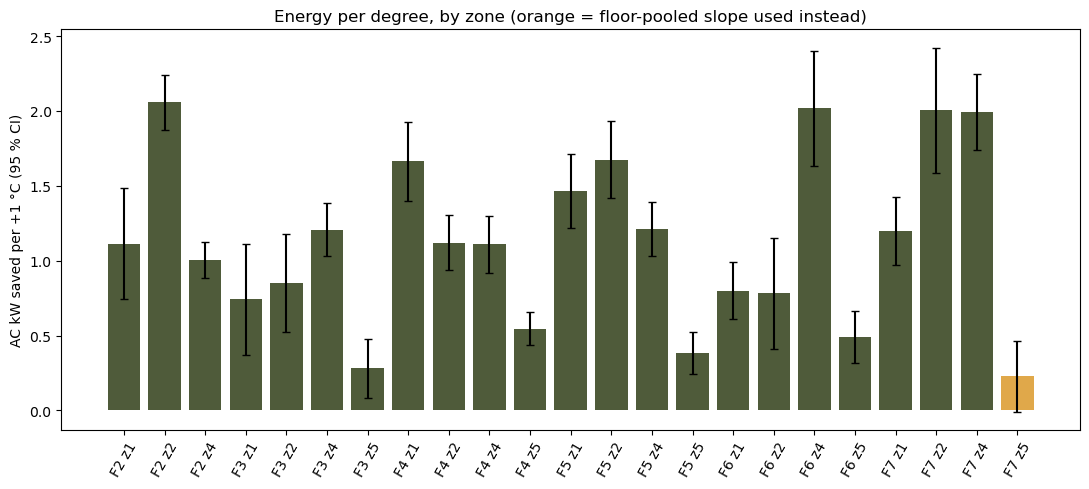

In [4]:
pct = slopes["saving_pct_per_c"]
print(f"AC saved per +1 °C: median {pct.median():.1f} % of the zone's AC "
      f"(range {pct.min():.1f}-{pct.max():.1f} %), compared with a typical 6-10 % per °C")
print(f"Zones using the floor-pooled slope: "
      f"{', '.join('F' + slopes.loc[slopes['source'] != 'zone', 'floor'].astype(str) + ' ' + slopes.loc[slopes['source'] != 'zone', 'zone']) or 'none'}")
print(f"Moisture: a zone 1 °C warmer holds {slopes['moisture_g_per_kg_per_c'].median():.2f} g/kg more water (median)")

labels = "F" + slopes["floor"].astype(str) + " " + slopes["zone"]
err = np.vstack([slopes["zone_kw_per_c"] - slopes["ci_low"], slopes["ci_high"] - slopes["zone_kw_per_c"]])
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["#4f5b3a" if s == "zone" else "#e0a84a" for s in slopes["source"]]
ax.bar(labels, -slopes["zone_kw_per_c"], yerr=err, color=colors, capsize=3)
ax.set_ylabel("AC kW saved per +1 °C (95 % CI)")
ax.set_title("Energy per degree, by zone (orange = floor-pooled slope used instead)")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
fig.savefig(SETPOINT_DIR / "energy_per_degree.png", dpi=130)
plt.show()